# Зерно для офиса: от CRM к очереди удержания

## 1. Цель и навигация

Руководитель B2B получает список с положительным сценарным ожиданием, максимум 150 звонков. [Список](reports/call_list_2026-09-30.csv), [денежные допущения](models/office_churn/1.0/passport.json), [команда запуска и лимит 3](README.md). На позднем квартале модель выбрала 66 офисов и дала 260 021 ₽ условной годовой ценности при удержании 50%, против отрицательных простых правил. Это не измеренная прибыль кампании.

Структура взята из публичного пустого шаблона: цель, данные, предобработка, анализ и модели, выводы. Код и содержание написаны самостоятельно из брифа. Чистый запуск воспроизводит уже зафиксированное решение: первый выбор и первое открытие теста сохранены в `selection-before-test.json` и `reports/*-run.txt`. Повтор не является новым независимым тестом.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Image
from src.features import read_tables, clean_tables, build_features, build_target, snapshot, FEATURES
from src.analysis import develop, evaluate, package
RANDOM_STATE=42
DATA=Path('data')
for lib in (np,pd,matplotlib,sklearn): print(lib.__name__,lib.__version__)
print('Python',sys.version.split()[0])

numpy 2.4.6
pandas 3.0.6
matplotlib 3.10.9
sklearn 1.8.0
Python 3.12.14


**Вывод по окружению.** Версии библиотек выведены из текущего ядра, случайность закреплена числом 42. Все пути проекта относительные; это позволяет аналитику повторить расчёт в другом каталоге. Точные версии для переноса сохранены в requirements.txt.

## 2. Данные и аудит

SQLite выгружен 1 октября 2026, наблюдения заканчиваются 30 сентября. Клиент, договор, заказ, обращение и счёт имеют разную гранулярность: соединяем агрегаты по `client_id`, чтобы не размножать заказы при присоединении обращений. Базу открываем только для чтения: опечатка не должна создавать пустой SQLite.

In [2]:
tables=read_tables(DATA/'office.db')
audit=pd.DataFrame({'rows':{n:len(f) for n,f in tables.items()}})
display(audit)
print('Тестовые:',int(tables['clients'].is_test.sum()))
print('Дубли tickets ID:',int(tables['tickets'].ticket_id.duplicated().sum()))
print('Возвраты:',int((tables['orders'].status=='возврат').sum()))
print('Пропуск industry до/после исключения тестовых:',int(tables['clients'].industry.isna().sum()),int(clean_tables(tables)['clients'].industry.isna().sum()))
print('Последний заказ:',tables['orders'].order_date.max())

,rows
clients,1503
contracts,1503
orders,67695
tickets,3416
invoices,12951


Тестовые: 3
Дубли tickets ID: 142
Возвраты: 673
Пропуск industry до/после исключения тестовых: 78 75
Последний заказ: 2026-09-30


**Вывод по данным.** 1 503 клиента включают 3 тестовых; 67 695 заказов включают 673 возврата и 1 407 отмен. В 3 416 строках обращений 142 повтора ID, их удаляем. Пропуски отрасли: 78 во всей таблице, 75 у настоящих клиентов; заполняем «нет данных». Отрицательные возвраты сохраняем как реальные деньги, отмены исключаем. CRM не наблюдает назначение звонков и контроль, поэтому причинное удержание по ней не измерить.

## 3. Предобработка и время

Общий код находится в `src/features.py`, его вызывает и `score.py`. Договор действует, если начался не позже среза и завершился после него либо ещё не завершён. Цель зрелая только при `cutoff + MonthEnd(3) <= 2026-09-30`; рабочий квартал неизвестен. Окно заказов и обращений: `(cutoff − 90 дней; cutoff]`; предыдущие 90 дней нужны для тренда. Оплата после среза неизвестна. Масштабирование, one-hot и заполнение чисел обучаются только внутри pipeline.

Три ранних среза — разработка, июнь — поздняя проверка, сентябрь — работа. Разные срезы одного офиса остаются в одной группе CV.

In [3]:
clean=clean_tables(tables)
for c in ['2025-09-30','2025-12-31','2026-03-31']:
    y=build_target(tables,c)
    print(c,len(y),round(y.mean(),3))
f=build_features(tables,'2026-06-30')
print('Июнь признаки:',f.shape)
print(f[['orders_90','revenue_90','days_since_order','late_share_90','tickets_90','pay_late_last3']].mean())
assert build_target(tables,'2026-09-30').isna().all()
print('Сентябрьская цель целиком неизвестна.')

2025-09-30 628 0.065
2025-12-31 763 0.073
2026-03-31 888 0.13


Июнь признаки: (965, 16)
orders_90              13.230052
revenue_90          39915.847990
days_since_order        9.150259
late_share_90           0.080267
tickets_90              0.622798
pay_late_last3          0.943696
dtype: float64
Сентябрьская цель целиком неизвестна.


**Вывод по предобработке.** На ранних срезах 628 / 763 / 888 активных офисов, уход 6,5 / 7,3 / 13,0%. Всего 2 279 строк и 985 разных клиентов. В июне 965 строк: среднее число заказов 13,230, выручка за 90 дней 39 915,848 ₽, дней с последнего заказа 9,150. Рабочий срез содержит 1 027 строк без будущей цели. Нулевая метка там была бы ошибкой.

## 4. Исследование, гипотеза и выбор модели

До позднего теста сравниваем Dummy и три семейства на общих пяти GroupKFold. Основной критерий — средний ROC-AUC; если LogReg в пределах 0,005 от лидера, выбираем её как более простую. AP дополняет оценку редкого класса. Гипотезу о различии Уфы проверяем на мартовском срезе: одно наблюдение на офис. Графики объединяют ранние строки, поэтому знаменатели — офис-кварталы, а не независимые офисы.

Следующая ячейка воспроизводит этап разработки: записывает разбиения, метрики, OOF-калибровку и фиксирует выбор до `evaluate`.

AUDIT {'clients': 1503, 'contracts': 1503, 'orders': 67695, 'tickets': 3416, 'invoices': 12951, 'n_test': 3, 'duplicates_tickets': 142, 'returns': 673, 'missing_industry': 78} TRAIN (2279, 19) 985
              n      rate
cutoff                   
2025-09-30  628  0.065287
2025-12-31  763  0.073394
2026-03-31  888  0.129505
HYPOTHESIS {'cutoff': '2026-03-31', 'hypothesis': 'Частота ухода в Уфе равна остальным городам', 'n': 888, 'contingency': {0: {False: 655, True: 118}, 1: {False: 68, True: 47}}, 'odds_ratio': 3.836615154536391, 'p_value': 1.6574949161734954e-09, 'limitation': 'Наблюдательная ассоциация; один квартал, без причинной идентификации.'}


           roc_auc           average_precision          
              mean       std              mean       std
model                                                   
boosting  0.764348  0.049001          0.404180  0.069100
dummy     0.500000  0.000000          0.093029  0.007628
knn       0.723568  0.044597          0.335443  0.054003
logreg    0.792080  0.042640          0.391782  0.034956
OOF CALIBRATION                        n    mean_p  observed
(-0.000846, 0.0161]  456  0.007910  0.015351
(0.0161, 0.035]      456  0.025207  0.030702
(0.035, 0.0694]      455  0.049459  0.063736
(0.0694, 0.137]      456  0.096889  0.083333
(0.137, 0.983]       456  0.292379  0.271930 BRIER 0.0708404356247782
PAST MONEY [{'cutoff': '2025-09-30', 'n_calls': 34, 'expected': 134343.72963110762, 'conditional_observed': -43033.064}, {'cutoff': '2025-12-31', 'n_calls': 46, 'expected': 318363.67274483474, 'conditional_observed': 25118.509999999937}, {'cutoff': '2026-03-31', 'n_calls': 64, 'expected': 

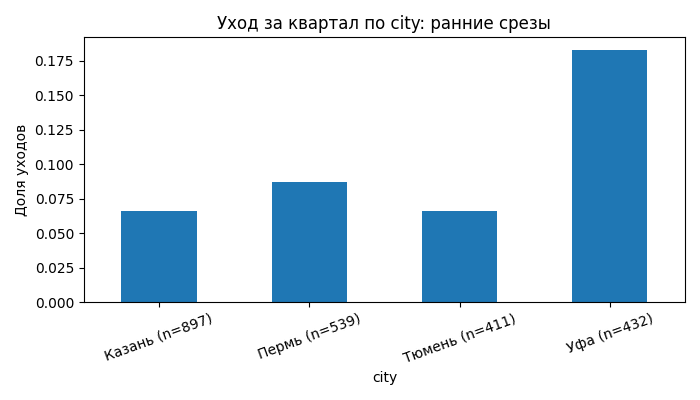

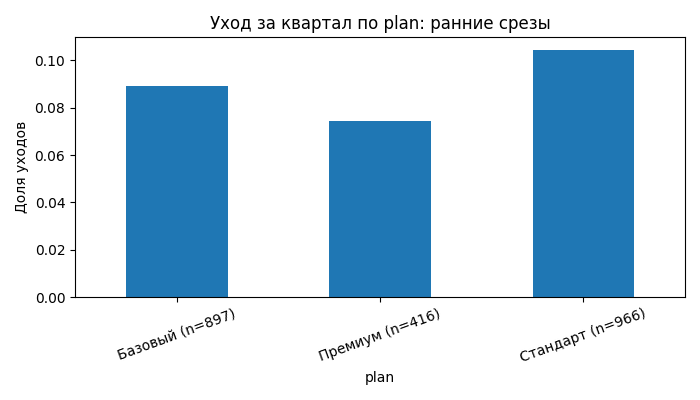

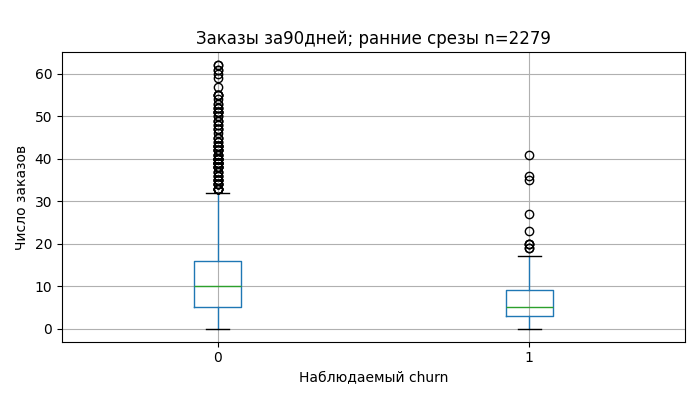

roc_auc           average_precision          
              mean       std              mean       std
model                                                   
boosting  0.764348  0.049001          0.404180  0.069100
dummy     0.500000  0.000000          0.093029  0.007628
knn       0.723568  0.044597          0.335443  0.054003
logreg    0.792080  0.042640          0.391782  0.034956

,Unnamed: 0,n,mean_p,observed
0,"(-0.000846, 0.0161]",456,0.007910,0.015351
1,"(0.0161, 0.035]",456,0.025207,0.030702
2,"(0.035, 0.0694]",455,0.049459,0.063736
3,"(0.0694, 0.137]",456,0.096889,0.083333
4,"(0.137, 0.983]",456,0.292379,0.271930


,cutoff,n_calls,expected,conditional_observed
0,2025-09-30,34,134343.729631,-43033.064000
1,2025-12-31,46,318363.672745,25118.510000
2,2026-03-31,64,253198.756956,-11919.258667


In [4]:
decision=develop()
print('Выбор до теста:',decision['chosen'])
for name in ['churn-by-city','churn-by-plan','orders-by-churn']:
    display(Image(filename=f'reports/{name}.png'))
display(pd.read_csv('reports/cv-folds.csv').groupby('model')[['roc_auc','average_precision']].agg(['mean','std']))
display(pd.read_csv('reports/calibration-oof.csv'))
display(pd.read_csv('reports/development-money.csv'))

**Вывод по анализу и выбору.** LogReg: AUC 0,792 против 0,764 у бустинга, 0,724 у kNN и 0,5 у Dummy. AP 0,392 против 0,404 у бустинга. Критерий AUC записан заранее, дополнительная AP его не меняет. На мартовском срезе в Уфе ушли 47 из 165 офисов, в остальных городах 68 из 723; Fisher p ≈ 1,66e−9, OR 3,84. Это связь, а не доказательство причины в доставке.

Верхний OOF-квинтиль: средний риск 0,292, частота 0,272; Brier 0,07084. Вероятности не идеально совпадают с частотами. Главное ограничение: прошлые очереди на 34 / 46 / 64 звонка дают условные −43 033 / +25 119 / −11 919 ₽ при положительном ожидании. Высокая AUC не гарантирует полезные деньги. До июньского теста это записано в `reports/decision-note-before-test.md`; июнь не используется для новой настройки.

### Поздний квартал и деньги

Формула: `p × save × 0.35 × 12 × (revenue_90 / 3) − 1500 − 0.2 × (revenue_90 / 3)`. Удержание 50% — допущение, не измерение этой CRM. По прогнозам выбираем положительное ожидание и максимум 150 звонков; затем в исторической сценарной оценке заменяем вероятность наблюдаемым уходом. Сравниваем отказ, 150 офисов с минимальным трендом и всех. Обзвон всех превышает ресурс 150, но показывает цену неадресного подхода.

In [5]:
test_metrics=evaluate()
display(pd.Series(test_metrics))
display(pd.read_csv('reports/test-known-new.csv'))
display(pd.read_csv('reports/sensitivity.csv'))

FROZEN CHOICE logreg TEST {'roc_auc': 0.8360609222545627, 'average_precision': 0.5303784468644185, 'brier': 0.09088380414133268, 'n': 965, 'churn_rate': 0.13575129533678756, 'mean_p': 0.08879744211775743, 'n_calls': 66, 'caught': 34, 'expected': 343084.3008012404, 'conditional_profit': 260021.15033333327, 'rule_profit': -227323.863, 'all_profit': -2446568.5710000005, 'no_calls': 0} KNOWN/NEW [{'known': False, 'n': 192, 'rate': 0.21354166666666666, 'mean_p': 0.11583714305983472, 'queue_n': 11, 'queue_mean_p': 0.4444562549065139, 'queue_churn_rate': 0.6363636363636364}, {'known': True, 'n': 773, 'rate': 0.11642949547218628, 'mean_p': 0.08208124214249374, 'queue_n': 55, 'queue_mean_p': 0.44770289028742144, 'queue_churn_rate': 0.4909090909090909}] SENSITIVITY [{'save_rate': 0.3, 'fixed_profit': 58009.64833333333, 'reselected_n': 34, 'reselected_profit': 70038.0668}, {'save_rate': 0.5, 'fixed_profit': 260021.15033333327, 'reselected_n': 66, 'reselected_profit': 260021.15033333327}, {'save_r

roc_auc               8.360609e-01
average_precision     5.303784e-01
brier                 9.088380e-02
n                     9.650000e+02
churn_rate            1.357513e-01
mean_p                8.879744e-02
n_calls               6.600000e+01
caught                3.400000e+01
expected              3.430843e+05
conditional_profit    2.600212e+05
rule_profit          -2.273239e+05
all_profit           -2.446569e+06
no_calls              0.000000e+00
dtype: float64

,known,n,rate,mean_p,queue_n,queue_mean_p,queue_churn_rate
0,False,192,0.213542,0.115837,11,0.444456,0.636364
1,True,773,0.116429,0.082081,55,0.447703,0.490909


,save_rate,fixed_profit,reselected_n,reselected_profit
0,0.3,58009.648333,34,70038.066800
1,0.5,260021.150333,66,260021.150333
2,0.7,462032.652333,97,501392.034600


**Вывод по поздней проверке.** AUC 0,8361, AP 0,5304, Brier 0,09088. Средний риск 0,0888 против наблюдаемого ухода 0,1358: на будущем квартале риск недооценён. Выбрано 66 звонков, из них 34 наблюдаемых ухода. Условный результат 260 021 ₽ против правила −227 324 ₽, всех −2 446 569 ₽ и отказа 0. Ожидание очереди 343 084 ₽ отличается от сценария по меткам.

Знакомых офисов 773, новых 192. Частоты ухода 0,1164 / 0,2135, средний риск 0,0821 / 0,1158. В очереди 55 знакомых (средний риск 0,4477, уход 0,4909) и 11 новых (риск 0,4445, уход 0,6364). Число 11 мало для надёжной калибровки. Проверка будущего квартала и ранее невиданных офисов отвечает на разные вопросы.

При удержании 30 / 50 / 70% фиксированная очередь даёт 58 010 / 260 021 / 462 033 ₽. При перевыборе: 34 / 66 / 97 контактов и 70 038 / 260 021 / 501 392 ₽. Это условная годовая ценность удержания за вычетом скидки и времени, а не измеренная прибыль квартала.

### На что опирается модель и что проверить

В ранних данных у Уфы 18,3% ухода (432 офис-квартала), в других городах 6,6–8,7%. У «Стандарта» 10,5% (966), «Премиума» 7,5% (416). У ушедших меньше заказов. Коэффициенты LogReg на подготовленных признаках: число заказов около −1,27, число обращений +0,84, Уфа +0,54. Это условные линейные связи, а не эффект вмешательства. Менеджера и кофемашину могли намеренно выдавать лояльным крупным офисам.

Гипотезы: проблемы доставки увеличивают недовольство в Уфе; повышение цены «Стандарта» ускоряет уход. Следующая проверка — сравнить сроки доставки до и после смены подрядчика и провести управляемый пилот качества доставки; по тарифу — контролируемое предложение сохранения цены или дополнительной ценности. Город и коэффициент отрасли сами по себе не устанавливают причину.

После фиксации поздней оценки отдельно проверил отрасль на тех же групповых фолдах: без неё AUC 0,79432 против 0,79208. Улучшение от отрасли не подтверждается; коэффициенты отраслей не стоит превращать в рекомендации. Выпущенная версия и политика после теста не менялись. Журнал: `reports/industry-ablation.json`.


In [6]:
coef=pd.read_csv('reports/coefficients.csv',index_col=0).iloc[:,0]
display(pd.concat([coef.head(5),coef.tail(5)]))

num__orders_90              -1.272371
cat__industry_IT            -0.450210
cat__industry_финансы       -0.363455
num__own_machine            -0.328344
num__has_manager            -0.314237
cat__industry_госсектор      0.241129
cat__industry_услуги         0.255515
cat__industry_образование    0.426523
cat__city_Уфа                0.544221
num__tickets_90              0.843429
Name: 0, dtype: float64

### Выпуск и пересчёт

После фиксации поздней оценки обучаем модель на 3 244 размеченных строках. Июньские метрики относятся к модели на ранних срезах, а не к переобученной версии. Паспорт записывает дату, схему, версии, экономику, хеш, лимит и сумму полной точности. Контрольные 20 разных офисов проверяют перенос вычислений с допуском 1e−9, а не обобщение.

In [7]:
passport=package()
print('Рабочих офисов:',len(build_features(tables,'2026-09-30')))
print('Звонков:',passport['n_calls'],'сценарное ожидание:',passport['expected_profit'])
print('Goldenmaxdiff:',passport['golden_max_diff'])
display(pd.read_csv('reports/call_list_2026-09-30.csv').head())
display(pd.read_csv('reports/working-known-new.csv'))

PACKAGE 1027 65 443403 goldendiff 9.454242944073599e-17
Рабочих офисов: 1027
Звонков: 65 сценарное ожидание: 443403
Goldenmaxdiff: 9.454242944073599e-17


,client_id,city,p_churn,exp_profit
0,C0115,Уфа,0.364,49502
1,C1263,Уфа,0.511,37908
2,C1247,Уфа,0.921,37464
3,C0186,Пермь,0.817,35959
4,C0383,Казань,0.207,33803


,known,n,mean_p
0,False,193,0.110717
1,True,834,0.077462


**Вывод по выпуску.** Рабочий список содержит 65 офисов, условное ожидание 443 403 ₽; контроль 20 строк сошёлся с максимальной разницей 9,45e−17. Рабочая цель неизвестна. По размеченным срезам знакомы 834 офиса, 193 новых; частоты ухода рабочего квартала пока нет. Команда с лимитом 3: `python score.py --cutoff 2026-09-30 --call-limit 3`. Изменять ячейки не требуется.



## 5. Рекомендации руководителю

1. Передать очередь 65 офисов как сценарный приоритет и проверять её пилотом. Исторические 260 тыс. ₽ лучше правил, но ранние OOF-деньги неустойчивы.
2. Проверить причинное удержание случайным назначением звонка и контролем. Учесть малую мощность 65 контактов, заранее задать горизонт и стоимость.
3. Контролировать калибровку в дорогой очереди, у новых офисов и по городам, а также временной дрейф. Обычная AUC этого не заменяет.
4. Проверять доставку в Уфе, поддержку и ценность тарифов как гипотезы механизма. Не объявлять коэффициент причиной.
5. Пересчитывать список общим `score.py`, сохранять метаданные, проверять golden после переноса. При лимите 3 использовать CLI: не отрезать случайные строки из округлённого списка.